# JRA 2024〜2026 データ探索とモデル確認

`src/train.py` の関数を読み込んで、データの傾向とモデルの挙動をグラフで確認するノートブックです。
上から順に実行してください（Run All で全部動きます）。

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import train as T  # noqa: E402

# macOS の日本語フォント
plt.rcParams["font.family"] = "Hiragino Sans"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Hiragino Sans")
pd.set_option("display.max_columns", 50)

## 1. データの読み込みと概要

In [2]:
df = T.add_features(T.load())
print(f"{df.race_id.nunique()} レース / {len(df)} 頭 / 期間 {df.date.min():%Y-%m-%d} 〜 {df.date.max():%Y-%m-%d}")
df.head()

9423 レース / 129282 頭 / 期間 2024-01-06 〜 2026-09-27


,race_id,date,venue,kai,nichi,race_no,weather,going,surface,course,distance,race_class,handicap,start_time,finish,waku,umaban,horse_name,sex,age,color,carried_weight,base_weight,jockey_mark,jockey,...,prev_early_pos,mean_early_pos,front_rate,mean_last_corner_pos,mean_gain,wet_mean_finish_rate,wet_runs,dry_mean_finish_rate,wet_diff,wet_behind_diff,wet_fit_today,cond_mean_finish_rate,n_front_runners,jockey_top3_rate_z,trainer_top3_rate_z,horse_mean_finish_rate_z,mean_behind_z,carried_weight_z,body_weight_z,age_z,horse_top3_rate_z,best_finish_rate_z,mean_mkt_prob_z,mean_early_pos_z,cond_mean_finish_rate_z
0,2024_00001,2024-01-06,中山,1,1,1,晴,良,ダート,ダート・右,1200,未勝利,0,10:05,16.0,1,1,コーストガード,牡,3,青鹿,54.0,57.0,▲,佐藤翔馬,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-1.420023,0.004829,NaN,NaN,NaN,NaN,NaN,NaN
1,2024_00001,2024-01-06,中山,1,1,1,晴,良,ダート,ダート・右,1200,未勝利,0,10:05,7.0,1,2,ミッキードラマー,牡,3,鹿,57.0,57.0,NaN,菊沢一樹,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0.930360,2.245369,NaN,NaN,NaN,NaN,NaN,NaN
2,2024_00001,2024-01-06,中山,1,1,1,晴,良,ダート,ダート・右,1200,未勝利,0,10:05,14.0,2,3,エテルノアキーロ,牡,3,鹿,57.0,57.0,NaN,黛弘人,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0.930360,-0.535991,NaN,NaN,NaN,NaN,NaN,NaN
3,2024_00001,2024-01-06,中山,1,1,1,晴,良,ダート,ダート・右,1200,未勝利,0,10:05,4.0,2,4,グリントリッター,セ,3,鹿,57.0,57.0,NaN,石川裕紀人,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0.930360,-1.926672,NaN,NaN,NaN,NaN,NaN,NaN
4,2024_00001,2024-01-06,中山,1,1,1,晴,良,ダート,ダート・右,1200,未勝利,0,10:05,13.0,3,5,ラスジャン,牡,3,鹿,57.0,57.0,NaN,内田博幸,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0.930360,-0.381471,NaN,NaN,NaN,NaN,NaN,NaN


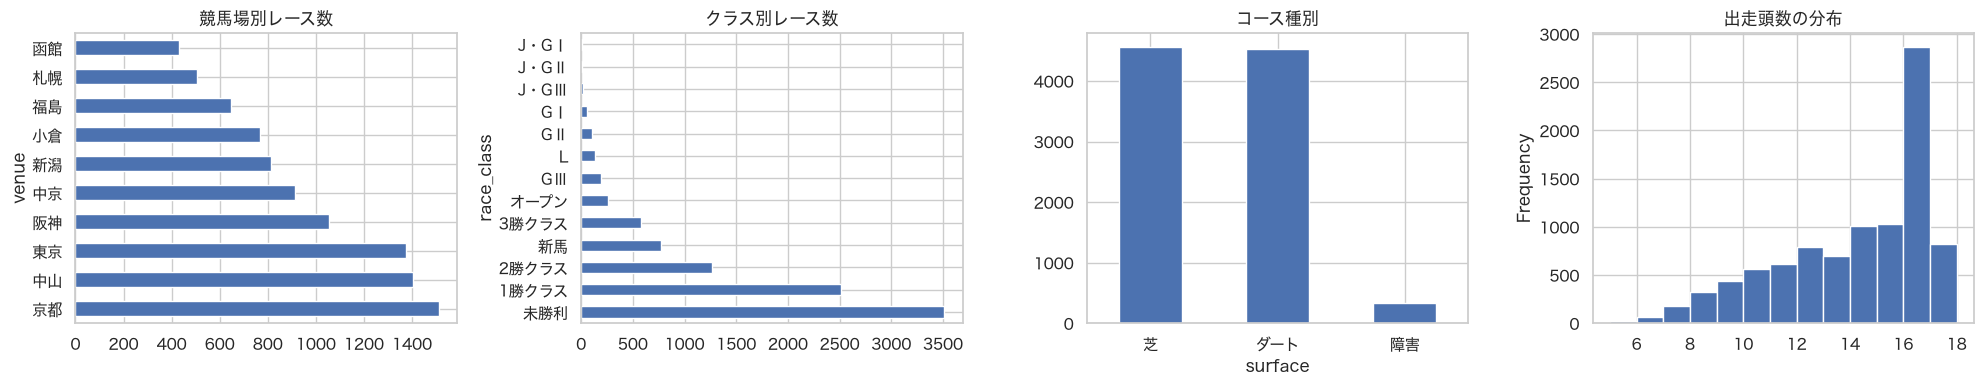

In [3]:
races = df.drop_duplicates("race_id")
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
races["venue"].value_counts().plot.barh(ax=axes[0], title="競馬場別レース数")
races["race_class"].value_counts().plot.barh(ax=axes[1], title="クラス別レース数")
races["surface"].value_counts().plot.bar(ax=axes[2], title="コース種別", rot=0)
races["num_runners"].plot.hist(ax=axes[3], bins=range(5, 19), title="出走頭数の分布")
plt.tight_layout()

## 2. 人気別の成績

人気が成績をどれだけ説明するか。単勝回収率が100%を超える人気帯はあるか。

,頭数,勝率,複勝率,単勝回収率
1,9622,33.4%,65.7%,78.9%
2,9406,19.9%,52.4%,80.8%
3,9401,13.1%,41.4%,76.6%
4,9409,8.8%,33.9%,72.1%
5,9378,6.9%,25.8%,76.4%
6,9370,5.0%,21.1%,76.5%
7,9306,3.7%,16.3%,75.3%
8,9155,2.9%,12.8%,79.7%
9,8806,2.1%,9.9%,76.1%
10+,45429,0.8%,4.4%,63.5%


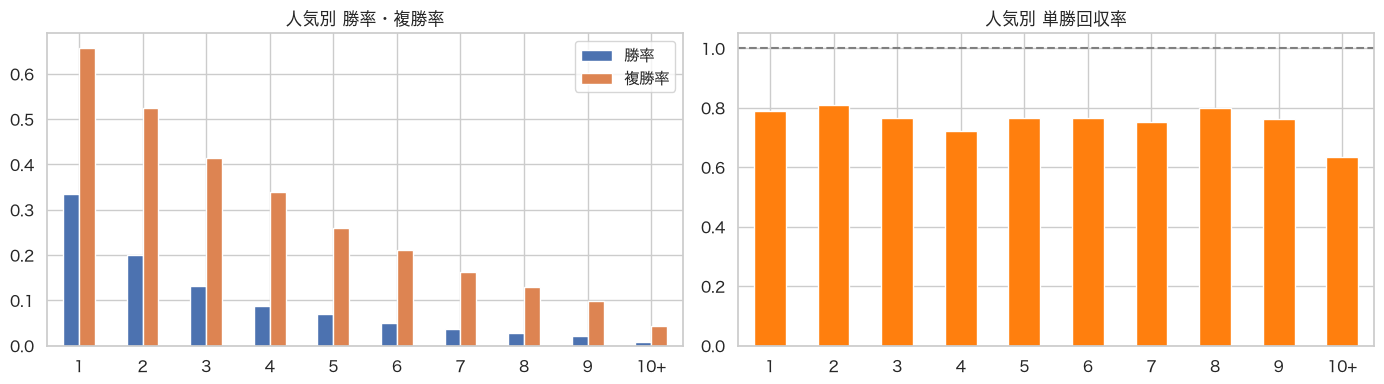

In [4]:
pop = (df.dropna(subset=["popularity"])
         .assign(popularity=lambda d: d.popularity.clip(upper=10).astype(int),
                 ret=lambda d: d.win * d.odds)
         .groupby("popularity")
         .agg(頭数=("win", "size"), 勝率=("win", "mean"), 複勝率=("top3", "mean"), 単勝回収率=("ret", "mean")))
pop.index = [f"{i}" if i < 10 else "10+" for i in pop.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pop[["勝率", "複勝率"]].plot.bar(ax=axes[0], rot=0, title="人気別 勝率・複勝率")
pop["単勝回収率"].plot.bar(ax=axes[1], rot=0, color="tab:orange", title="人気別 単勝回収率")
axes[1].axhline(1.0, color="gray", ls="--")
plt.tight_layout()
pop.style.format({"勝率": "{:.1%}", "複勝率": "{:.1%}", "単勝回収率": "{:.1%}"})

## 3. 枠番・馬体重増減と複勝率

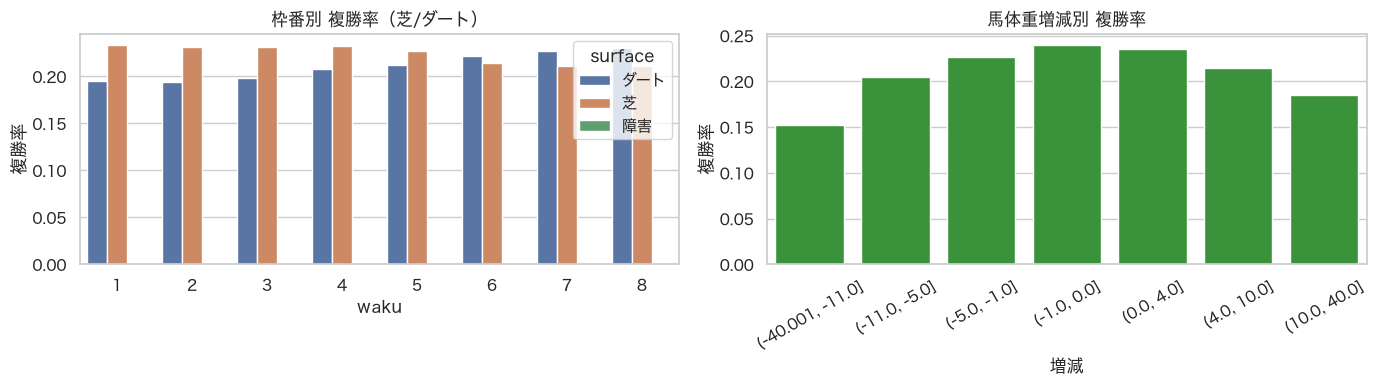

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
flat = df[df.surface != "障害"]
sns.barplot(data=flat, x="waku", y="top3", hue="surface", errorbar=None, ax=axes[0])
axes[0].set(title="枠番別 複勝率（芝/ダート）", ylabel="複勝率")

bins = [-40, -11, -5, -1, 0, 4, 10, 40]
diff = df.dropna(subset=["body_weight_diff"]).assign(
    増減=lambda d: pd.cut(d.body_weight_diff, bins=bins, include_lowest=True))
sns.barplot(data=diff, x="増減", y="top3", errorbar=None, ax=axes[1], color="tab:green")
axes[1].set(title="馬体重増減別 複勝率", ylabel="複勝率")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

## 4. 騎手別の成績（騎乗数上位20人）

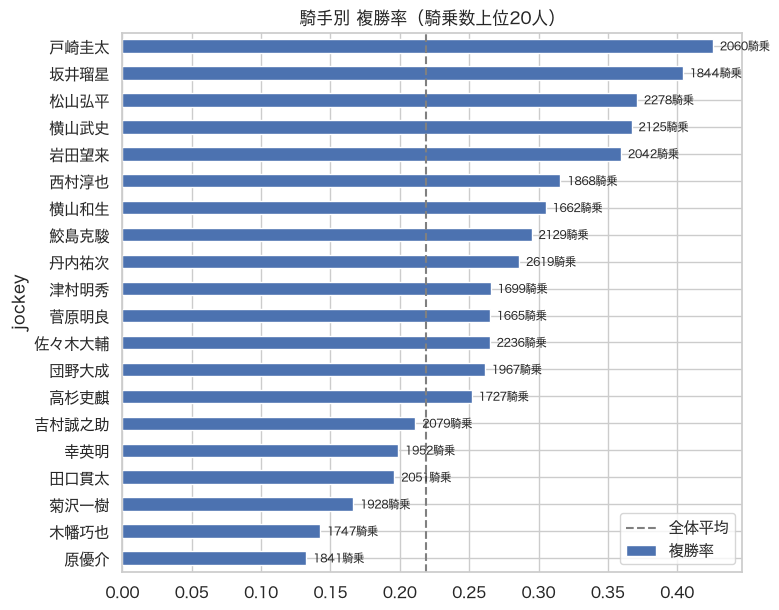

In [6]:
jk = (df.groupby("jockey")
        .agg(騎乗数=("top3", "size"), 勝率=("win", "mean"), 複勝率=("top3", "mean"))
        .sort_values("騎乗数", ascending=False).head(20)
        .sort_values("複勝率"))
ax = jk["複勝率"].plot.barh(figsize=(8, 7), title="騎手別 複勝率（騎乗数上位20人）")
ax.axvline(df.top3.mean(), color="gray", ls="--", label="全体平均")
ax.legend()
for i, n in enumerate(jk["騎乗数"]):
    ax.text(jk["複勝率"].iloc[i] + 0.005, i, f"{n}騎乗", va="center", fontsize=8)

## 4b. 脚質・気象と複勝率

左: そのレースの序盤の位置（結果）と複勝率。前にいた馬ほど3着以内に残りやすい。
中: 過去平均の序盤の位置（レース前に分かる脚質）と複勝率。右: 発走時の気温と複勝率（気温自体はレース内の全馬に共通なので、差はほぼ出ない）。

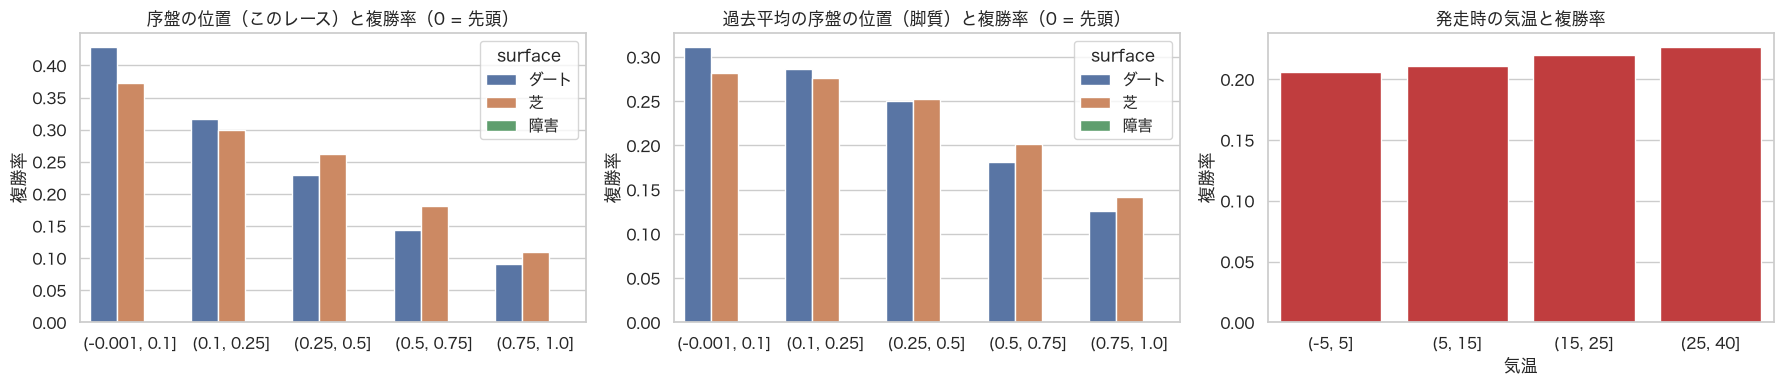

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
pos_bins = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
flat = df[df.surface != "障害"]
for ax, col, title in [(axes[0], "early_pos", "序盤の位置（このレース）"), (axes[1], "mean_early_pos", "過去平均の序盤の位置（脚質）")]:
    x = flat.dropna(subset=[col]).assign(区分=lambda d: pd.cut(d[col], pos_bins, include_lowest=True))
    sns.barplot(data=x, x="区分", y="top3", hue="surface", errorbar=None, ax=ax)
    ax.set(title=f"{title}と複勝率（0 = 先頭）", ylabel="複勝率", xlabel="")
x = df.assign(気温=pd.cut(df.temp, [-5, 5, 15, 25, 40]))
sns.barplot(data=x, x="気温", y="top3", errorbar=None, ax=axes[2], color="tab:red")
axes[2].set(title="発走時の気温と複勝率", ylabel="複勝率")
plt.tight_layout()

## 5. モデルの確認

ウォークフォワード（2026年3〜9月の各月を、それより前のデータ（2024年〜）で学習して予測）の結果を見ます。
`USE_ODDS = False` にすると、オッズを使わない能力モデルだけの結果になります。

In [8]:
USE_ODDS = True

from sklearn.metrics import log_loss, roc_auc_score

test, model = T.walk_forward(df, use_odds=USE_ODDS)
base = T.market_baseline(df)
for name, p in [("モデル", test), ("参考: オッズだけ", base)]:
    print(f"{name:14s} AUC {roc_auc_score(p.top3, p.prob):.3f}  LogLoss {log_loss(p.top3, p.prob):.3f}")
T.evaluate_bets(test, test.prob)

モデル            AUC 0.821  LogLoss 0.406
参考: オッズだけ      AUC 0.821  LogLoss 0.405


,戦略,レース数,勝率,複勝率,単勝回収率
0,モデル最上位,1956,0.330266,0.654908,0.775869
1,1番人気,1956,0.333845,0.657975,0.788344


### 2段目の係数

オッズありのとき、市場の勝率と能力モデルの予測をどの程度の重みで組み合わせているか（最後の月の学習結果）。

In [9]:
if USE_ODDS:
    print(pd.Series(model.stacker.coef_[0], index=["市場の勝率(log)", "能力モデル(logit)", "頭数(log)"]).round(3))

市場の勝率(log)      0.974
能力モデル(logit)    0.060
頭数(log)        -0.511
dtype: float64


### 能力モデルの特徴量の重要度（Permutation Importance）

9月のデータで（8月までで学習したモデル）、各特徴量をシャッフルしたときに AUC がどれだけ下がるか。

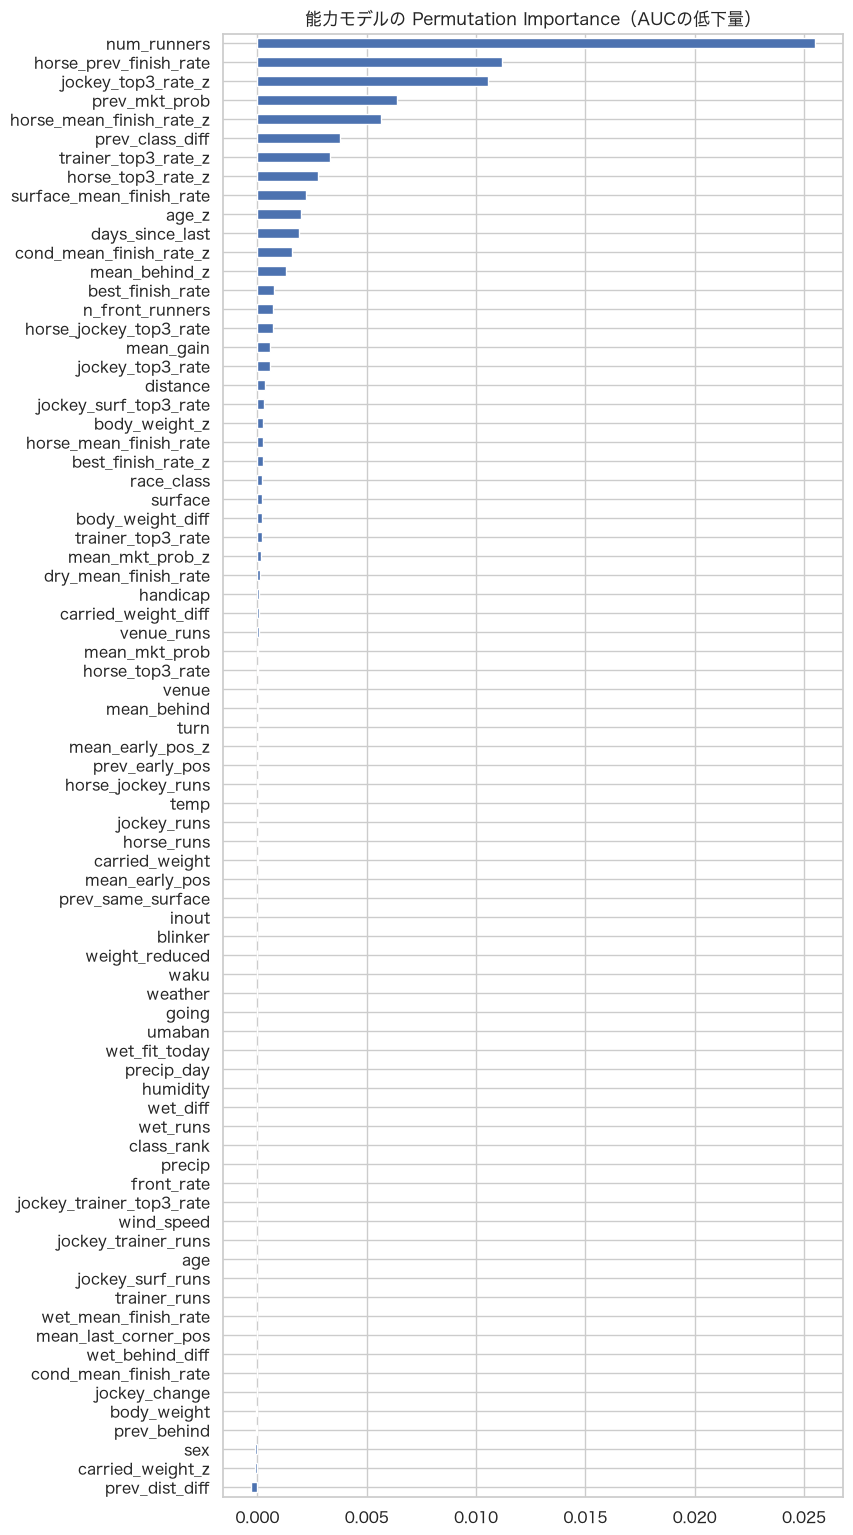

In [10]:
from sklearn.inspection import permutation_importance

last = df[df.month == T.TEST_MONTHS[-1]]
pi = permutation_importance(model.ability, last[T.FEATURES], last.top3, scoring="roc_auc",
                            n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=T.FEATURES).sort_values()
imp.plot.barh(figsize=(8, 19), title="能力モデルの Permutation Importance（AUCの低下量）");

### 予測確率は当たっているか（キャリブレーション）

予測確率を10分割し、実際の複勝率と比べます。対角線に近いほど確率として信頼できます。

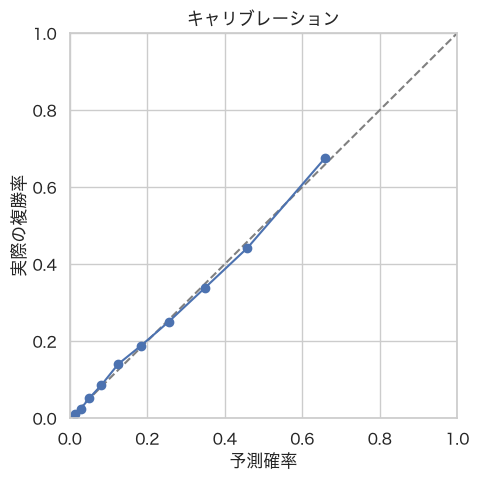

In [11]:
cal = (test.assign(bin=pd.qcut(test.prob, 10, duplicates="drop"))
           .groupby("bin", observed=True).agg(予測=("prob", "mean"), 実際=("top3", "mean"), 頭数=("top3", "size")))
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.plot(cal["予測"], cal["実際"], "o-")
ax.set(xlabel="予測確率", ylabel="実際の複勝率", title="キャリブレーション", xlim=(0, 1), ylim=(0, 1));

### 予測と人気の関係

モデルが人気とどれだけ違う評価をしているか。

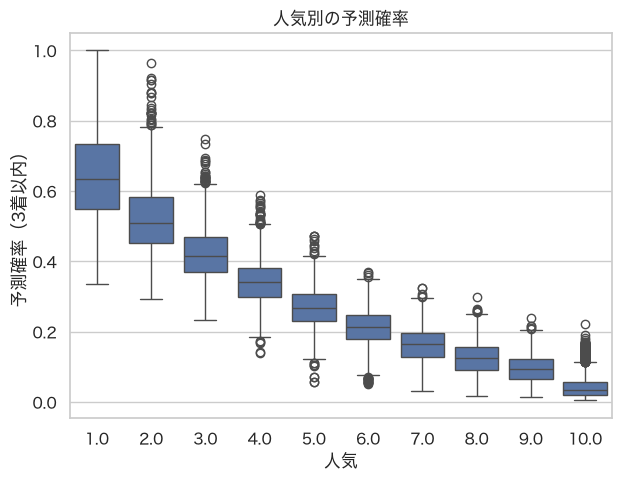

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=test.assign(人気=test.popularity.clip(upper=10)), x="人気", y="prob", ax=ax)
ax.set(title="人気別の予測確率", ylabel="予測確率（3着以内）");

## 6. レース単位で確認

`RACE_ID` を変えると、任意のレースの予測と結果を並べて見られます。

In [13]:
RACE_ID = test.race_id.iloc[0]

r = test[test.race_id == RACE_ID]
info = r.iloc[0]
print(f"{info.race_id} {info.date:%Y-%m-%d} {info.race_no}R {info.race_class} {info.surface}{info.distance}m 馬場:{info.going}")
(r[["umaban", "horse_name", "jockey", "odds", "popularity", "prob", "finish"]]
   .sort_values("prob", ascending=False)
   .style.format({"prob": "{:.1%}", "odds": "{:.1f}", "popularity": "{:.0f}", "finish": "{:.0f}"})
   .background_gradient(subset=["prob"], cmap="Blues"))

2026_06013 2026-03-01 1R 未勝利 ダート1800m 馬場:稍重


,umaban,horse_name,jockey,odds,popularity,prob,finish
102690,6,サラサチャチャチャ,江田照男,3.9,1,50.9%,2
102691,7,イデアクリスタル,横山和生,4.9,3,45.9%,5
102685,1,バイアブランカ,津村明秀,4.9,3,44.4%,4
102699,15,ピュアエンブレム,岩田康誠,4.8,2,44.0%,1
102692,8,ロジマギー,丸山元気,8.1,5,33.9%,3
102696,12,ロココ,長浜鴻緒,8.4,6,31.1%,6
102698,14,タートルインメイ,松岡正海,19.4,7,16.9%,14
102686,2,ビレッジルイーザ,荻野極,23.2,8,14.3%,9
102697,13,エリザベスタウン,原優介,71.7,9,4.9%,11
102693,9,フライスカイハイ,吉田豊,112.7,10,3.4%,7


## 7. 市場（オッズ）と比べて良いか

`src/evaluate.py` で、モデルがオッズより良いかを、信頼区間つきで確認します（月ごとに学習し直すので数分かかります）。

- **勝ち馬の予測**: 市場の勝率に、3着以内を目的にした能力モデル／勝ちを目的にした能力モデルを足したときの、勝ち馬の対数尤度の改善（1レースあたり）
- **3着以内**: オッズありモデルとオッズだけのモデルの、LogLoss・レース内AUCの差
- **校正**: モデルが市場より高く評価した馬は、実際にその分、結果が良いか
- **期待値ごとの単勝回収率**: モデルの勝率 × オッズ が1を超える馬を買えば、実際に儲かるか
- **複勝**: 実際の複勝払戻で、モデルの期待値（3着内確率 × 予想払戻）が高い馬を買えば、実際に儲かるか

In [14]:
import evaluate as E

pred = E.collect_predictions(df)
r = E.report(pred)
E.print_report(r, pred)
E.print_place(r)

/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


/Users/yumurasho/keiba_data/keiba_prediction/src/evaluate.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  outs.append(test.assign(


評価: 1956レース / 26597頭（ウォークフォワード）

■ 1. 勝ち馬の予測（1レースあたりの対数尤度。0に近いほど良い。区間は市場（補正あり）との差の95%区間）
              モデル  対数尤度/レース  市場（補正あり）との差                 区間     判定
      市場（オッズそのまま）   -1.9248      +0.0000                          
         市場（補正あり）   -1.9249      +0.0000                          
     市場＋3着内の能力モデル   -1.9221      +0.0027 [+0.0008, +0.0048] 市場より良い
      市場＋勝ちの能力モデル   -1.9228      +0.0021 [+0.0004, +0.0038] 市場より良い
            市場＋両方   -1.9221      +0.0027 [+0.0008, +0.0047] 市場より良い
勝ちの能力モデル単独（オッズなし）   -2.1365      -0.2117 [-0.2383, -0.1856] 市場より悪い
  係数（月ごと）市場＋3着内: 市場 +1.08 +1.08 +1.08 +1.08 +1.09 +1.09 +1.10 / 3着内能力 -0.08 -0.07 -0.09 -0.09 -0.09 -0.10 -0.11
  係数（月ごと）市場＋勝ち  : 市場 +1.08 +1.07 +1.07 +1.08 +1.08 +1.08 +1.09 / 勝ち能力 -0.07 -0.06 -0.06 -0.07 -0.07 -0.08 -0.09
  期待値・校正には「市場＋3着内の能力モデル」を使用

■ 2. 3着以内の予測
         モデル  AUC（全体）  AUC（レース内の平均）  LogLoss
  市場（オッズ＋頭数）   0.8206        0.8005   0.4054
能力モデル（オッズなし）   0.7858        0.7635   0.4346
    オッズありモデル   0.8206        0.8009   0.4

### 期待値ごとの単勝回収率（誤差の範囲つき）\n\n点が実際の回収率、棒が95%区間（誤差の約1.96倍）、×が予想の回収率。100%（破線）を区間ごと上回る区分があれば、割安な馬を見つけられている。

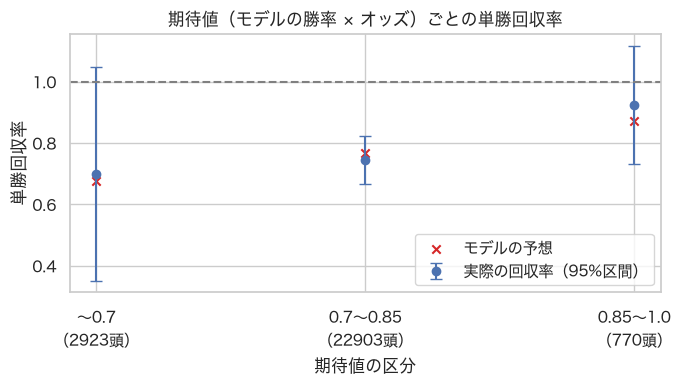

In [15]:
roi = r["roi"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(roi))
ax.errorbar(x, roi["実際の回収率"], yerr=1.96 * roi["誤差"], fmt="o", capsize=4, label="実際の回収率（95%区間）")
ax.scatter(x, roi["予想の回収率"], marker="x", color="tab:red", label="モデルの予想")
ax.axhline(1.0, color="gray", ls="--")
ax.set_xticks(x)
ax.set_xticklabels([f"{i}\n（{n}頭）" for i, n in zip(roi.index, roi["頭数"])])
ax.set(title="期待値（モデルの勝率 × オッズ）ごとの単勝回収率", xlabel="期待値の区分", ylabel="単勝回収率")
ax.legend()
plt.tight_layout()